# บทที่ 8 ฟังก์ชัน

**รายวิชา:** การเขียนโปรแกรมด้วยภาษาไพธอน 3
**ผู้สอน:** ผศ.พิศาล สุขขี
สาขาวิชาวิทยาการคอมพิวเตอร์ คณะศิลปศาสตร์และวิทยาศาสตร์ มหาวิทยาลัยราชภัฏศรีสะเกษ

---

บทที่ผ่านมาเราได้ใช้ **ฟังก์ชันที่มีอยู่ในภาษา (Built-in Function)** เช่น `print()`, `input()`, `len()`, `range()` ซึ่งเรียกใช้ได้ทันที บทนี้จะเรียนรู้ **ฟังก์ชันที่ผู้ใช้สร้างเอง (User-defined Function)** เพื่อออกแบบโปรแกรมแก้ปัญหาแบบแยกย่อยการทำงานได้สะดวกขึ้น

> 📌 **ฟังก์ชัน (Function)** คือ **กลุ่มคำสั่งที่ทำหน้าที่อย่างเฉพาะเจาะจง** แยกการทำงานออกจากโปรแกรมอย่างอิสระ และ **ทำงานเมื่อถูกเรียกใช้เท่านั้น**

**ประโยชน์ของการแบ่งโปรแกรมเป็นฟังก์ชัน**
- **แบ่งปัญหาใหญ่เป็นส่วนย่อย** ทำให้บริหารจัดการและแก้ไขโปรแกรมขนาดใหญ่ได้ง่าย (ทักษะการแยกส่วนประกอบจากบทที่ 2)
- **หลีกเลี่ยงโค้ดซ้ำซ้อน** โดยเขียนครั้งเดียวแล้วเรียกใช้ได้หลายครั้ง
- **นำกลับมาใช้ใหม่ (Reuse)** ได้ในโปรแกรมอื่น
- **ทดสอบได้ง่าย** ทดสอบทีละฟังก์ชันได้ (เหมือนเซลล์ตรวจคำตอบในบทที่ผ่านมา)

### 🎯 วัตถุประสงค์การเรียนรู้
เมื่อศึกษาบทเรียนนี้จบ ผู้เรียนจะสามารถ
1. สร้างฟังก์ชันด้วย `def` เขียน docstring และเรียกใช้ฟังก์ชันได้
2. ส่งค่ากลับจากฟังก์ชันด้วย `return` ทั้งค่าเดียวและหลายค่าได้
3. อธิบายขอบเขตและเวลาชีวิตของตัวแปร (Local / Global) ได้
4. อธิบายการส่งผ่านอาร์กิวเมนต์ในไพธอน และป้องกันการแก้ไขข้อมูลโดยไม่ตั้งใจได้
5. ใช้อาร์กิวเมนต์ประเภท Required, Keyword, Default และ Variable-length ได้
6. เขียนฟังก์ชันแบบเวียนเกิด (Recursive) และเปรียบเทียบกับการวนซ้ำได้
7. ออกแบบโปรแกรมโดยแยกงานเป็นฟังก์ชันได้

### 📖 วิธีใช้ Notebook นี้
- กด **Shift + Enter** ที่เซลล์โค้ดเพื่อรัน โดยรันเรียงจากบนลงล่าง (ฟังก์ชันต้องถูกนิยามก่อนจึงจะเรียกใช้ได้)
- กล่อง **🧠 ตรวจสอบความเข้าใจ** ให้คิดก่อนเปิดเฉลย และกล่อง **✍️ ลงมือทำ** มีเซลล์ตรวจคำตอบอัตโนมัติ

## 📑 สารบัญ
- [8.1 พื้นฐานของฟังก์ชัน](#s81)
- [8.2 การใช้งานฟังก์ชัน](#s82) · การเรียกฟังก์ชัน · Docstring · `return`
- [8.3 ขอบเขตและเวลาชีวิตของตัวแปร](#s83)
- [8.4 การส่งผ่านอาร์กิวเมนต์](#s84)
- [8.5 ประเภทของอาร์กิวเมนต์](#s85) · Required · Keyword · Default · Variable-length
- [8.6 ฟังก์ชันแบบเวียนเกิด](#s86) · แฟกทอเรียล · ฟีโบนัชชี
- [8.7 การออกแบบโปรแกรมโดยใช้ฟังก์ชัน (ตู้ ATM)](#s87)
- [8.8 สรุป](#s88) · [8.9 คำถามท้ายบท](#s89) · [8.10 บรรณานุกรม](#s810)

<a id="s81"></a>
## 8.1 พื้นฐานของฟังก์ชัน
ฟังก์ชันเป็นวิธีเขียนโปรแกรมแบบมีโครงสร้าง โดยรวบรวมชุดคำสั่งที่ใช้บ่อยและมีหน้าที่ชัดเจนไว้เป็นกลุ่มเดียวกัน แล้วสั่งงานผ่านการเรียกชื่อฟังก์ชัน ไวยากรณ์การสร้างฟังก์ชันในไพธอน

```python
def function_name(parameters):
    """docstring"""
    statement(s)
    return value
```

| ลำดับ | องค์ประกอบ | คำอธิบาย |
|---|---|---|
| 1 | คำหลัก **`def`** | ส่วนหัว จุดเริ่มต้นของการนิยามฟังก์ชัน (ย่อมาจาก define) |
| 2 | **ชื่อฟังก์ชัน** | ระบุตัวตน ไม่ซ้ำกับฟังก์ชันอื่น และตั้งตามกฎเดียวกับชื่อตัวแปร (นิยมใช้ snake_case เช่น `calc_area`) |
| 3 | **พารามิเตอร์** ในวงเล็บ | ตัวแปรรับค่าที่ส่งเข้ามา จะมีหรือไม่มีก็ได้ (แต่ต้องมีวงเล็บเสมอ) |
| 4 | เครื่องหมาย **`:`** | ปิดท้ายส่วนหัวของฟังก์ชัน |
| 5 | **docstring** | สตริงอธิบายหน้าที่ของฟังก์ชัน (ไม่บังคับ แต่ควรมี) |
| 6 | **ตัวฟังก์ชัน (body)** | ชุดคำสั่งที่ **เยื้องหน้า** (4 ช่องว่าง) เพื่อแสดงว่าอยู่ในฟังก์ชัน |
| 7 | คำสั่ง **`return`** | ส่งค่ากลับ (ไม่บังคับ) |

In [ ]:
def greet(name):
    """ฟังก์ชันนี้สำหรับพิมพ์ข้อความทักทาย
    บุคคลที่ผ่านเข้ามาทางช่อง parameter"""
    print("Hello, " + name + ". Good morning!")

print("นิยามฟังก์ชัน greet แล้ว แต่ยังไม่มีอะไรเกิดขึ้น เพราะยังไม่ได้เรียกใช้")

> 💡 การรันเซลล์ที่มี `def` **เป็นเพียงการนิยาม (สร้าง) ฟังก์ชัน** คำสั่งข้างในยังไม่ทำงานจนกว่าจะถูกเรียกใช้

<a id="s82"></a>
## 8.2 การใช้งานฟังก์ชัน

### 8.2.1 การเรียกฟังก์ชัน
เมื่อนิยามฟังก์ชันแล้ว เรียกใช้ได้จากโปรแกรมหลัก จากฟังก์ชันอื่น หรือจากไพธอนเชลล์ โดยพิมพ์ **ชื่อฟังก์ชันตามด้วยวงเล็บ** และใส่อาร์กิวเมนต์ (ถ้ามี) เรียกซ้ำได้กี่ครั้งก็ได้

<p align="center">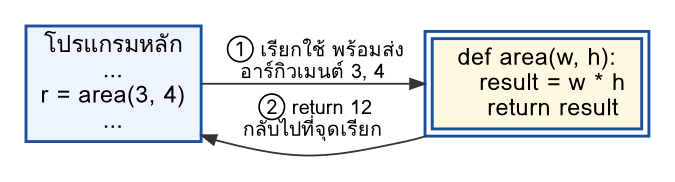<br><b>แผนภาพ</b> การเรียกใช้ฟังก์ชันและการส่งค่ากลับ</p>

In [ ]:
greet('Paul')
greet('สมชาย')
for person in ["Ann", "Bee", "Cat"]:   # เรียกซ้ำได้หลายครั้ง
    greet(person)

In [ ]:
# ❌ เรียกใช้ฟังก์ชันก่อนนิยาม -> NameError
say_hi()

def say_hi():
    print("Hi!")

### 8.2.2 Docstring
**Docstring** คือสตริงแรกหลังส่วนหัวของฟังก์ชัน ใช้อธิบายว่าฟังก์ชันทำอะไร แม้จะเป็นเอกสารเสริม แต่ **เป็นแนวทางการเขียนโปรแกรมที่ดี** (ทบทวนขั้นการจัดทำเอกสารในบทที่ 2) นิยมใช้ Triple Quote เพื่อเขียนได้หลายบรรทัด และเรียกดูได้ผ่าน **แอตทริบิวต์ `__doc__`** หรือฟังก์ชัน `help()`

In [ ]:
print(greet.__doc__)

In [ ]:
help(greet)

> 💡 ใน Jupyter ให้พิมพ์ `greet(` แล้วกด **Shift + Tab** จะเห็น docstring แสดงขึ้นมา ซึ่ง docstring ของฟังก์ชัน Built-in ก็เรียกดูวิธีนี้ได้ เช่น `help(len)`

### 8.2.3 การคืนค่าจากฟังก์ชันด้วยคำสั่ง `return`
`return` ใช้ **ออกจากฟังก์ชันและส่งค่ากลับ** ไปยังจุดที่เรียกใช้
```python
return [expression_list]
```
- ส่งกลับได้ทั้งค่าคงที่ ตัวแปร หรือนิพจน์ และ **ส่งกลับได้มากกว่า 1 ค่า**
- เมื่อทำคำสั่ง `return` แล้ว **คำสั่งที่เหลือในฟังก์ชันจะไม่ทำงาน**
- ฟังก์ชันที่ **ไม่มี `return`** (หรือ `return` เฉย ๆ) จะคืนค่า **`None`**

In [ ]:
print(greet("May"))     # greet ไม่มี return จึงได้ None

In [ ]:
def absolute_value(num):
    """ฟังก์ชันนี้จะส่งกลับค่าสัมบูรณ์
    ของหมายเลขที่ป้อนเข้ามาทางพารามิเตอร์"""
    if num >= 0:
        return num
    else:
        return -num

print(absolute_value(2))     # 2
print(absolute_value(-4))    # 4

<div style="border-left:5px solid #d9480f;padding:8px 14px;background:rgba(217,72,15,.08)">

### ⚠️ ความต่างระหว่าง `print` กับ `return`
- `print()` **แสดงผลบนจอ** เท่านั้น นำค่าไปคำนวณต่อไม่ได้
- `return` **ส่งค่ากลับ** ให้ผู้เรียก ซึ่งนำไปเก็บในตัวแปร คำนวณต่อ หรือแสดงผลก็ได้

ฟังก์ชันที่ดีควร **คืนค่า (return)** และให้ผู้เรียกตัดสินใจเองว่าจะทำอะไรกับค่านั้น
</div>

In [ ]:
def area_print(w, h):
    print(w * h)          # แสดงผลอย่างเดียว

def area_return(w, h):
    return w * h          # ส่งค่ากลับ

a = area_print(3, 4)      # แสดง 12 แต่ a ได้ None
b = area_return(3, 4)     # ไม่แสดงอะไร แต่ b ได้ 12
print("a =", a, "| b =", b)
print("พื้นที่รวม 2 ห้อง =", area_return(3, 4) + area_return(5, 2))

In [ ]:
# return หลายค่า (ไพธอนรวมเป็นทูเพิลให้) แล้ว unpack ออกเป็นหลายตัวแปร
def min_max_avg(numbers):
    return min(numbers), max(numbers), sum(numbers) / len(numbers)

result = min_max_avg([72, 95, 58, 88])
print(result, type(result))
lo, hi, avg = min_max_avg([72, 95, 58, 88])
print(f"ต่ำสุด {lo} สูงสุด {hi} เฉลี่ย {avg:.2f}")

<div style="border-left:5px solid #1971c2;padding:8px 14px;background:rgba(25,113,194,.08)">

### ✍️ ลงมือทำ 1: ฟังก์ชันแรกของฉัน
1. เขียนฟังก์ชัน `circle_area(r)` คืนค่าพื้นที่วงกลม (π r²) ปัดทศนิยม 2 ตำแหน่ง (ใช้ `math.pi` และ `round()`)
2. เขียนฟังก์ชัน `celsius_to_fahrenheit(c)` คืนค่าองศาฟาเรนไฮต์ = c × 9/5 + 32
3. เขียนฟังก์ชัน `is_even(n)` คืนค่า `True` ถ้า n เป็นเลขคู่ ไม่เช่นนั้นคืน `False`

อย่าลืมเขียน docstring ให้ทุกฟังก์ชัน
</div>

In [ ]:
import math

def circle_area(r):
    pass

def celsius_to_fahrenheit(c):
    pass

def is_even(n):
    pass

In [ ]:
# ✅ เซลล์ตรวจคำตอบ
import io as _io, contextlib as _cl
def _capture(func, *args):
    _buf = _io.StringIO()
    try:
        with _cl.redirect_stdout(_buf):
            func(*args)
    except Exception as _e:
        return f"เกิดข้อผิดพลาด: {_e}"
    return _buf.getvalue()
def _safe(f, *a):
    try:
        return f(*a)
    except Exception as _e:
        return f"เกิดข้อผิดพลาด: {type(_e).__name__}: {_e}"
_tests = [("circle_area(7)", _safe(circle_area, 7), 153.94), ("circle_area(1)", _safe(circle_area, 1), 3.14), ("c_to_f(100)", _safe(celsius_to_fahrenheit, 100), 212.0), ("c_to_f(-40)", _safe(celsius_to_fahrenheit, -40), -40.0), ("is_even(10)", _safe(is_even, 10), True), ("is_even(7)", _safe(is_even, 7), False), ("มี docstring ครบ", all(f.__doc__ for f in (circle_area, celsius_to_fahrenheit, is_even)), True)]
_ok = 0
for _label, _got, _exp in _tests:
    _pass = _got == _exp
    _ok += _pass
    _show = repr(_got) if len(repr(_got)) < 70 else repr(_got)[:67] + "..."
    print(f"{'✅' if _pass else '❌'} {_label} = {_show}" + ("" if _pass else f"\n      ควรได้ {_exp!r}"[:200]))
print(f"\nผ่าน {_ok}/{len(_tests)} ข้อ" + ("  🎉" if _ok == len(_tests) else ""))

<details><summary><b>💡 ดูเฉลย</b></summary>

```python
def circle_area(r):
    """คืนค่าพื้นที่วงกลมรัศมี r ปัดทศนิยม 2 ตำแหน่ง"""
    return round(math.pi * r ** 2, 2)

def celsius_to_fahrenheit(c):
    """แปลงองศาเซลเซียสเป็นฟาเรนไฮต์"""
    return c * 9 / 5 + 32

def is_even(n):
    """คืนค่า True ถ้า n เป็นเลขคู่"""
    return n % 2 == 0
```
</details>

<a id="s83"></a>
## 8.3 ขอบเขตและเวลาชีวิตของตัวแปร
- **ขอบเขตของตัวแปร (Scope)** คือส่วนของโปรแกรมที่ "มองเห็น" ตัวแปรนั้น
- **เวลาชีวิตของตัวแปร (Lifetime)** คือช่วงเวลาที่ตัวแปรอยู่ในหน่วยความจำ

| | ตัวแปร Local | ตัวแปร Global |
|---|---|---|
| ที่มา | กำหนดค่า **ภายในฟังก์ชัน** (รวมถึงพารามิเตอร์) | กำหนดค่า **นอกฟังก์ชัน** (ระดับโปรแกรมหลัก) |
| มองเห็นจาก | ภายในฟังก์ชันนั้นเท่านั้น | ทุกที่ในโปรแกรม (อ่านค่าได้จากในฟังก์ชัน) |
| เวลาชีวิต | **ตราบที่ฟังก์ชันกำลังทำงาน** และถูกทำลายเมื่อฟังก์ชันจบ ฟังก์ชันจึงไม่จำค่าจากการเรียกครั้งก่อน | ตลอดการทำงานของโปรแกรม |

In [ ]:
def my_func():
    x = 10                                 # x ตัวนี้เป็น local (คนละตัวกับ x ข้างนอก)
    print("Value inside function:", x)

x = 20                                     # x ตัวนี้เป็น global
my_func()
print("Value outside function:", x)

แม้ `my_func()` จะกำหนด `x = 10` แต่ **ไม่กระทบตัวแปร `x` ภายนอก** เพราะเป็นตัวแปร 2 ตัวที่ชื่อเหมือนกันแต่ขอบเขตต่างกัน

```
 ┌─ Global ──────────────────────────┐
 │  x = 20                           │
 │   ┌─ Local ของ my_func() ──────┐  │
 │   │  x = 10   (เกิดเมื่อเรียก     │  │
 │   │            ตายเมื่อจบฟังก์ชัน) │  │
 │   └────────────────────────────┘  │
 └───────────────────────────────────┘
```

In [ ]:
# ตัวแปร local มองไม่เห็นจากภายนอก
def make_secret():
    secret = "1234"
    return "สร้างรหัสแล้ว"

print(make_secret())
print(secret)        # ❌ NameError: secret เป็น local ของ make_secret เท่านั้น

In [ ]:
# อ่านค่าตัวแปร global จากในฟังก์ชันได้
VAT_RATE = 0.07

def price_with_vat(price):
    return price * (1 + VAT_RATE)     # อ่าน VAT_RATE ได้

print(price_with_vat(100))

**การเปลี่ยนค่าตัวแปร Global จากในฟังก์ชัน** ต้องประกาศด้วยคำหลัก **`global`** ก่อน มิฉะนั้นไพธอนจะสร้างตัวแปร local ชื่อเดียวกันขึ้นมาใหม่

In [ ]:
def my_func():
    global x
    x = 10
    print("Value inside function:", x)

x = 20
my_func()
print("Value outside function:", x)    # x ข้างนอกถูกเปลี่ยนเป็น 10 ด้วย

In [ ]:
# ❌ อ่านแล้วเปลี่ยนค่า global โดยไม่ประกาศ global -> UnboundLocalError
counter = 0
def increase():
    counter = counter + 1    # ไพธอนถือว่า counter เป็น local แต่ยังไม่มีค่า
increase()

<div style="border-left:5px solid #d9480f;padding:8px 14px;background:rgba(217,72,15,.08)">

### ⚠️ ใช้ `global` เท่าที่จำเป็น
การให้ฟังก์ชันแก้ไขตัวแปร global ทำให้โปรแกรมติดตามและดีบักยาก (ไม่รู้ว่าฟังก์ชันไหนเปลี่ยนค่า) วิธีที่ดีกว่าคือ **ส่งค่าเข้าทางพารามิเตอร์ แล้วรับผลกลับด้วย `return`**
</div>

In [ ]:
def increase(counter):
    return counter + 1

counter = 0
counter = increase(counter)
counter = increase(counter)
print("counter =", counter)

<a id="s84"></a>
## 8.4 การส่งผ่านอาร์กิวเมนต์
ฟังก์ชันมักต้องการ **ข้อมูลตั้งต้น** จากผู้เรียก จึงมีตัวแปรพิเศษคือ **พารามิเตอร์** ไว้รับค่า

| คำศัพท์ | ความหมาย | ตัวอย่าง |
|---|---|---|
| **พารามิเตอร์ (Parameter)** | ตัวแปรที่ประกาศไว้ **ในส่วนหัวของฟังก์ชัน** | `def area(w, h):` ← `w`, `h` |
| **อาร์กิวเมนต์ (Argument)** | ค่าหรือตัวแปรที่ **ส่งเข้าไปตอนเรียกใช้** | `area(3, 4)` ← `3`, `4` |

ภาษาโปรแกรมทั่วไปส่งผ่านอาร์กิวเมนต์ได้ 2 แบบ

### 8.4.1 การส่งผ่านตามค่า (Pass by Value)
**คัดลอกค่า** ของตัวแปรจากผู้เรียกไปให้พารามิเตอร์ การแก้ไขภายในฟังก์ชันจึง **ไม่กระทบตัวแปรของผู้เรียก** พบในภาษา C และ C++ เป็นต้น

### 8.4.2 การส่งผ่านตามการอ้างอิง (Pass by Reference)
ส่ง **ที่อยู่ (address) สำหรับอ้างอิงข้อมูล** แทนสำเนา ซึ่ง **ประหยัดเวลาและหน่วยความจำ** เพราะไม่ต้องคัดลอก แต่ฟังก์ชัน **เปลี่ยนแปลงข้อมูลของผู้เรียกได้** จึงต้องระวังเป็นพิเศษ

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 ไพธอนส่งอาร์กิวเมนต์แบบใด? (Pass by Object Reference)
เอกสารต้นฉบับระบุว่าไพธอนส่งผ่านแบบ **pass-by-reference** ซึ่ง **ถูกเพียงบางส่วน** ที่ถูกต้องกว่าคือไพธอนส่งแบบ **"pass by object reference"** (หรือ *call by sharing / pass by assignment*) คือ **พารามิเตอร์เป็นอีกชื่อหนึ่งที่ชี้ไปยังวัตถุเดียวกับอาร์กิวเมนต์** (เหมือน `b = a` ในบทที่ 5) ผลที่เกิดขึ้นจึงขึ้นกับสิ่งที่ฟังก์ชันทำ

| สิ่งที่ฟังก์ชันทำ | ผลต่อตัวแปรของผู้เรียก | ดูเหมือน |
|---|---|---|
| **แก้ไขข้างใน** วัตถุที่แก้ไขได้ (mutable) เช่น `mylist.append(...)`, `d["k"] = v` | ✅ **เปลี่ยนตาม** | pass by reference |
| **กำหนดค่าใหม่** ให้พารามิเตอร์ เช่น `mylist = [...]`, `n = n + 1` | ❌ ไม่เปลี่ยน (พารามิเตอร์แค่ไปชี้วัตถุใหม่) | pass by value |
| ส่ง **วัตถุที่แก้ไขไม่ได้** (int, float, str, tuple) | ❌ ไม่เปลี่ยนเสมอ | pass by value |
</div>

In [ ]:
# กรณีที่ 1: แก้ไขข้างในลิสต์ (mutable) -> เปลี่ยนตามไปด้วย
def changeme(mylist):
    mylist.append([1, 2, 3, 4])       # การเปลี่ยนแปลงนี้สะท้อนออกไปนอกฟังก์ชันด้วย
    print("Values inside the function: {}".format(mylist))

mylist = [10, 20, 30]
changeme(mylist)
print("Values outside the function: {}".format(mylist))

In [ ]:
# กรณีที่ 2: กำหนดลิสต์ใหม่ให้พารามิเตอร์ -> ไม่กระทบข้างนอก
def replace_list(mylist):
    mylist = [1, 2, 3, 4]              # พารามิเตอร์ไปชี้ลิสต์ใหม่
    print("Values inside the function:", mylist)

mylist = [10, 20, 30]
replace_list(mylist)
print("Values outside the function:", mylist)

In [ ]:
# กรณีที่ 3: ส่งจำนวนเต็ม (immutable) -> ไม่กระทบข้างนอก
def add_bonus(score):
    score = score + 10
    print("ในฟังก์ชัน score =", score)

score = 70
add_bonus(score)
print("นอกฟังก์ชัน score =", score)

#### ป้องกันไม่ให้ฟังก์ชันแก้ไขข้อมูลของผู้เรียก
ถ้าต้องการแก้ไขลิสต์ภายในฟังก์ชันโดย **ไม่กระทบข้อมูลต้นฉบับ** ให้ **สำเนาเป็นตัวแปร local ก่อน** แล้วจึงแก้ไข

In [ ]:
import copy

def changeme(mylist):
    local_list = copy.copy(mylist)        # สำเนาก่อน (หรือใช้ mylist.copy() / mylist[:])
    local_list.append([1, 2, 3, 4])
    print("Values inside the function: {}".format(local_list))

mylist = [10, 20, 30]
changeme(mylist)
print("Values outside the function: {}".format(mylist))

> 💡 `copy.copy()` เป็น **สำเนาชั้นเดียว (shallow copy)** ถ้าลิสต์มีลิสต์ซ้อนอยู่ข้างใน ลิสต์ชั้นในยังเป็นตัวเดียวกัน ต้องใช้ **`copy.deepcopy()`** เพื่อสำเนาทุกชั้น

In [ ]:
import copy
nested = [[1, 2], [3, 4]]
shallow = copy.copy(nested)
deep = copy.deepcopy(nested)
nested[0].append(99)
print("shallow:", shallow)    # ลิสต์ชั้นในเปลี่ยนตาม
print("deep   :", deep)       # ไม่เปลี่ยน

<div style="border-left:5px solid #2b8a3e;padding:8px 14px;background:rgba(43,138,62,.08)">

### 🧠 ตรวจสอบความเข้าใจ (8.1–8.4)
1. ใน `def total(a, b):` และ `total(5, 7)` อะไรคือพารามิเตอร์ และอะไรคืออาร์กิวเมนต์
2. ฟังก์ชันที่ไม่มีคำสั่ง `return` คืนค่าอะไร
3. หลังรันโค้ดต่อไปนี้ `n` มีค่าเท่าใด: `def f(n): n = n * 2` / `n = 5` / `f(n)`
4. หลังรันโค้ดต่อไปนี้ `data` มีค่าเท่าใด: `def g(x): x.append(0)` / `data = [1]` / `g(data)`

<details><summary><b>คลิกเพื่อดูเฉลย</b></summary>

1. พารามิเตอร์คือ `a`, `b` และอาร์กิวเมนต์คือ `5`, `7`
2. `None`
3. **5** เพราะ int เปลี่ยนแปลงไม่ได้ และ `n = n * 2` เป็นการกำหนดค่าใหม่ให้ตัวแปร local
4. **[1, 0]** เพราะ `append` แก้ไขข้างในลิสต์ตัวเดียวกัน
</details>
</div>

<a id="s85"></a>
## 8.5 ประเภทของอาร์กิวเมนต์
การส่งอาร์กิวเมนต์ให้ฟังก์ชันมี 4 ประเภท ได้แก่ **Required**, **Keyword**, **Default** และ **Variable-length**

### 8.5.1 Required arguments
อาร์กิวเมนต์ที่ **ต้องส่งให้ครบ และเรียงตามลำดับตำแหน่ง** ตามที่ฟังก์ชันประกาศไว้ ถ้าไม่ครบจะเกิดข้อผิดพลาด `TypeError`

In [ ]:
def printme(text):
    "This prints a passed string into this function"
    print(text)

printme()      # ❌ ไม่ได้ส่งอาร์กิวเมนต์ -> TypeError

In [ ]:
def printinfo(name, age):
    print("Name: ", name)
    print("Age: ", age)

printinfo("miki", 50)       # "miki" -> name, 50 -> age ตามลำดับ

In [ ]:
printinfo(50, "miki")       # ⚠️ ไม่ error แต่ค่าสลับกัน เพราะส่งตามตำแหน่ง

### 8.5.2 Keyword arguments
ระบุ **ชื่อพารามิเตอร์ตอนเรียกใช้** (`ชื่อ=ค่า`) จึง **ไม่ต้องเรียงตามลำดับ** และอ่านเข้าใจง่ายกว่า

In [ ]:
printinfo(age=50, name="miki")
printinfo("miki", age=50)          # ผสมได้ แต่อาร์กิวเมนต์ตามตำแหน่งต้องมาก่อน keyword

In [ ]:
printinfo(name="miki", 50)         # ❌ ตำแหน่งตามหลัง keyword ไม่ได้ -> SyntaxError

### 8.5.3 Default arguments
กำหนด **ค่าปริยาย (ค่าเริ่มต้น)** ให้พารามิเตอร์ในส่วนหัว (`age=35`) ถ้าผู้เรียก **ไม่ส่งค่า** จะใช้ค่าปริยาย แต่ถ้าส่งมาจะใช้ค่าที่ส่งมาแทน โดย **พารามิเตอร์ที่มีค่าปริยายต้องอยู่หลังพารามิเตอร์ที่ไม่มีค่าปริยาย**

In [ ]:
def printinfo(name, age=35):
    print("Name: ", name)
    print("Age: ", age)
    print("---------")

printinfo(age=50, name="miki")     # ส่ง age มา -> ใช้ 50
printinfo(name="miki")             # ไม่ส่ง age -> ใช้ค่าปริยาย 35

พารามิเตอร์ `name` ไม่มีค่าปริยาย **ผู้เรียกจึงต้องส่งค่าให้ `name` เสมอ** ฟังก์ชัน Built-in หลายตัวก็ใช้ค่าปริยาย เช่น `print(..., sep=" ", end="\n")` และ `round(x, ndigits=None)`

<div style="border-left:5px solid #d9480f;padding:8px 14px;background:rgba(217,72,15,.08)">

### ⚠️ กับดัก: อย่าใช้ลิสต์เป็นค่าปริยาย
ค่าปริยายถูกสร้าง **ครั้งเดียวตอนนิยามฟังก์ชัน** ถ้าเป็นลิสต์ (mutable) ทุกการเรียกจะใช้ลิสต์ตัวเดียวกันสะสมไปเรื่อย ๆ วิธีที่ถูกคือใช้ `None` เป็นค่าปริยาย แล้วสร้างลิสต์ใหม่ในฟังก์ชัน
</div>

In [ ]:
def add_item_bad(item, basket=[]):       # ❌
    basket.append(item)
    return basket

print(add_item_bad("ไข่"))
print(add_item_bad("นม"))                # ได้ ['ไข่', 'นม'] ทั้งที่ควรได้ ['นม']

def add_item(item, basket=None):         # ✅
    if basket is None:
        basket = []
    basket.append(item)
    return basket

print(add_item("ไข่"))
print(add_item("นม"))

### 8.5.4 Variable-length arguments
ใช้เมื่อ **ไม่รู้ล่วงหน้าว่าจะส่งอาร์กิวเมนต์มากี่ตัว** โดยใส่ **เครื่องหมายดอกจัน `*`** หน้าชื่อพารามิเตอร์ อาร์กิวเมนต์ส่วนเกินทั้งหมดจะถูกรวมเป็น **ทูเพิล** (ถ้าไม่ได้ส่งมาจะเป็นทูเพิลว่าง)
```python
def functionname([formal_args,] *var_args_tuple):
    "function_docstring"
    function_suite
    return [expression]
```

In [ ]:
def printinfo(arg1, *vartuple):
    print("Output is: ")
    print(arg1)
    for var in vartuple:
        print(var)

printinfo(10)
printinfo(70, 60, 50)

In [ ]:
# ตัวอย่างประยุกต์: หาค่าเฉลี่ยของตัวเลขกี่ตัวก็ได้ (นิยมตั้งชื่อว่า *args)
def average(*args):
    if not args:
        return 0
    return sum(args) / len(args)

print(average(4, 8))
print(average(70, 85, 90, 65))
print(average())

> 💡 **เพิ่มเติม:** `**kwargs` (ดอกจัน 2 ตัว) รับ **keyword arguments จำนวนไม่จำกัด** และรวมเป็น **ดิกชันนารี**

In [ ]:
def student_card(name, **info):
    print(f"ชื่อ: {name}")
    for key, value in info.items():
        print(f"  {key}: {value}")

student_card("สมชาย", major="CS", year=2, gpa=3.45)

<a id="s86"></a>
## 8.6 ฟังก์ชันแบบเวียนเกิด (Recursive Function)
**ฟังก์ชันแบบเวียนเกิด** คือฟังก์ชันที่ **เรียกตัวเอง** ระหว่างการทำงาน ใช้แก้ปัญหาที่ **แบ่งเป็นปัญหาย่อยที่มีลักษณะเดียวกันแต่เล็กลง** ได้ เช่น การหาแฟกทอเรียล ฟีโบนัชชี การเรียงข้อมูลแบบ Quick Sort

ฟังก์ชันเวียนเกิดต้องมี 2 ส่วนเสมอ
1. **กรณีฐาน (Base case)** คือเงื่อนไขที่ **หยุดเรียกตัวเอง** และคืนค่าได้ทันที
2. **กรณีเวียนเกิด (Recursive case)** คือการเรียกตัวเองด้วย **ปัญหาที่เล็กลง** จนเข้าใกล้กรณีฐาน

### 8.6.1 การหาค่าแฟกทอเรียล
**แฟกทอเรียล** ของจำนวนเต็มไม่เป็นลบ n (เขียนว่า n!) คือผลคูณของจำนวนเต็มบวกทั้งหมดที่ ≤ n เช่น 5! = 5×4×3×2×1 = 120 และกำหนดให้ **0! = 1** (ตามหลักผลคูณว่าง) ในทางคณิตศาสตร์ n! คือจำนวนวิธีจัดเรียงของ n สิ่งที่แตกต่างกัน

**วิธีที่ 1: ใช้การวนซ้ำ**

In [ ]:
n = 5
result = 1
for i in range(n, 0, -1):
    result = result * i
print(result)

**วิธีที่ 2: ใช้ฟังก์ชันเวียนเกิด** โดยอาศัยนิยาม n! = n × (n−1)!

In [ ]:
def factorial(n):
    if n <= 1:                     # กรณีฐาน (ครอบคลุมทั้ง 0! และ 1!)
        return 1
    else:
        return n * factorial(n - 1)    # กรณีเวียนเกิด: ปัญหาเล็กลง 1

result = factorial(5)
print(result)
print("0! =", factorial(0))

<div style="border-left:5px solid #7048e8;padding:8px 14px;background:rgba(112,72,232,.08)">

### 🆕 หมายเหตุ: แก้ไขกรณีฐาน
เอกสารต้นฉบับใช้กรณีฐาน `if n == 1:` ซึ่งทำงานถูกต้องเมื่อ n ≥ 1 แต่ถ้าเรียก `factorial(0)` ฟังก์ชันจะเรียก `factorial(-1)`, `factorial(-2)`, … ไปเรื่อย ๆ ไม่มีวันถึง 1 จนเกิด **`RecursionError`** ใน Notebook นี้จึงแก้เป็น `if n <= 1:` ให้ได้ 0! = 1 ตามนิยาม
</div>

#### การทำงานของ `factorial(5)`
```
factorial(5)
= 5 * factorial(4)
= 5 * (4 * factorial(3))
= 5 * (4 * (3 * factorial(2)))
= 5 * (4 * (3 * (2 * factorial(1))))     ← ถึงกรณีฐาน คืนค่า 1
= 5 * (4 * (3 * (2 * 1)))                ← เริ่มคูณย้อนกลับ
= 120
```
เซลล์ด้านล่างแสดงการ "ลงไป" (เรียกตัวเอง) และ "ย้อนกลับขึ้นมา" (คืนค่า) ให้เห็นทีละขั้น

In [ ]:
def factorial_trace(n, depth=0):
    indent = "    " * depth
    print(f"{indent}เรียก factorial({n})")
    if n <= 1:
        print(f"{indent}-> กรณีฐาน คืนค่า 1")
        return 1
    result = n * factorial_trace(n - 1, depth + 1)
    print(f"{indent}<- factorial({n}) = {n} x factorial({n-1}) = {result}")
    return result

factorial_trace(5)

In [ ]:
# ❌ ฟังก์ชันเวียนเกิดที่ไม่มีกรณีฐาน -> RecursionError (ไพธอนจำกัดความลึกไว้ราว 1,000 ชั้น)
depth = 0
def countdown(n):
    global depth
    depth += 1
    if depth <= 5:
        print(n, end=" ")
    countdown(n - 1)          # ไม่มีเงื่อนไขหยุด!

try:
    countdown(5)
except RecursionError as e:
    print(f"... (เรียกตัวเองไป {depth:,} ชั้น)")
    print("RecursionError:", e)

**ประสิทธิภาพ:** การวนซ้ำมักมีประสิทธิภาพดีกว่า เพราะการเรียกฟังก์ชันแต่ละครั้งมีค่าใช้จ่าย (cost) ทั้งเวลาและหน่วยความจำ แต่ไม่เสมอไป ขึ้นกับลักษณะของงาน

### 8.6.2 จำนวนฟีโบนัชชี
**ตัวเลขฟีโบนัชชี (Fibonacci)** ตั้งชื่อตามนักคณิตศาสตร์ชาวอิตาลี **เลโอนาร์โดแห่งปิซา (Leonardo of Pisa)** หรือที่รู้จักในนาม ฟีโบนัชชี ซึ่งเผยแพร่ลำดับนี้ในต้นศตวรรษที่ 13 ลำดับเริ่มจาก 0 กับ 1 แล้ว **ตัวถัดไปคือผลบวกของสองตัวก่อนหน้า** และถูกนำไปใช้ในหลายด้าน รวมถึงการวิเคราะห์ทางเทคนิคในตลาดหุ้น (หาแนวรับ–แนวต้าน)

```
0, 1  →  0+1 = 1  →  0 1 1
      →  1+1 = 2  →  0 1 1 2
      →  1+2 = 3  →  0 1 1 2 3
      →  2+3 = 5  →  0 1 1 2 3 5  →  8, 13, 21, 34, 55, 89, 144, ...
```
$$F(0) = 0, \quad F(1) = 1, \quad F(n) = F(n-1) + F(n-2)$$

In [ ]:
# วิธีที่ 1: การวนซ้ำ
def fib(n):
    a, b = 0, 1
    for i in range(n):
        print(a, end=" ")
        a, b = b, a + b

fib(10)

In [ ]:
# วิธีที่ 2: ฟังก์ชันเวียนเกิด
def recur_fibo(n):
    if n <= 1:                       # กรณีฐาน: F(0) = 0, F(1) = 1
        return n
    else:
        return recur_fibo(n - 1) + recur_fibo(n - 2)

nterms = 10
for i in range(nterms):
    print(recur_fibo(i), end=" ")

#### 🔬 ทดลอง: เปรียบเทียบความเร็ว
`recur_fibo(n)` เรียกตัวเองซ้ำซ้อนจำนวนมาก เช่น `recur_fibo(5)` คำนวณ `recur_fibo(2)` ซ้ำถึง 3 ครั้ง จำนวนการเรียกจึงเพิ่มขึ้นแบบทวีคูณ ลองดูเวลาที่ใช้

In [ ]:
import time

def fib_loop(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

calls = 0
def fib_recur_count(n):
    global calls
    calls += 1
    return n if n <= 1 else fib_recur_count(n - 1) + fib_recur_count(n - 2)

for n in [10, 20, 25, 30]:
    calls = 0
    t0 = time.perf_counter(); r1 = fib_recur_count(n); t1 = time.perf_counter()
    r2 = fib_loop(n); t2 = time.perf_counter()
    print(f"F({n}) = {r1:<7} เวียนเกิด: {calls:>9,} ครั้ง {t1-t0:8.4f} วินาที | วนซ้ำ: {t2-t1:.6f} วินาที")

#### ข้อดีและข้อเสียของฟังก์ชันเวียนเกิด
| ข้อดี | ข้อเสีย |
|---|---|
| แก้ปัญหาด้วยการ **แบ่งเป็นปัญหาย่อย** ที่เล็กลง | สร้างตัวแปรและการเรียกฟังก์ชันจำนวนมาก **จึงเปลืองหน่วยความจำ** มากกว่าการวนซ้ำ |
| โค้ด **สั้น อ่านง่าย** ใกล้เคียงนิยามทางคณิตศาสตร์ | บางกรณี **ทำงานช้ากว่า** การวนซ้ำมาก (เช่น ฟีโบนัชชีแบบตรงไปตรงมา) |
| เหมาะกับปัญหาที่ซ้อนกันเป็นชั้นโดยไม่รู้จำนวนชั้นแน่นอน เช่น โครงสร้างโฟลเดอร์ ต้นไม้ข้อมูล | ถ้าลืมกรณีฐาน หรือข้อมูลลึกมาก จะเกิด `RecursionError` |
| ไม่เปลี่ยนค่าตัวแปรเดิม แต่สร้างตัวแปรใหม่ในแต่ละชั้น ซึ่งเป็นข้อดีต่อการเขียนโปรแกรมแบบขนานและเชิงฟังก์ชัน | ติดตามการทำงาน (ดีบัก) ยากกว่าสำหรับผู้เริ่มต้น |

<div style="border-left:5px solid #1971c2;padding:8px 14px;background:rgba(25,113,194,.08)">

### ✍️ ลงมือทำ 2: ฟังก์ชันเวียนเกิด
เขียนฟังก์ชันต่อไปนี้ **โดยใช้การเวียนเกิด (ห้ามใช้ลูป)**
1. `sum_to(n)` คืนค่า 1 + 2 + … + n (กรณีฐาน: `sum_to(0)` = 0) เช่น `sum_to(100)` → 5050
2. `power(base, exp)` คืนค่า base ยกกำลัง exp (exp ≥ 0, กรณีฐาน: exp = 0 ได้ 1) เช่น `power(2, 10)` → 1024
3. `reverse_text(s)` คืนค่าสตริงกลับหลัง (กรณีฐาน: สตริงว่าง) เช่น `reverse_text("abc")` → `"cba"` (คำใบ้: `s[-1] + reverse_text(s[:-1])`)
</div>

In [ ]:
def sum_to(n):
    pass

def power(base, exp):
    pass

def reverse_text(s):
    pass

In [ ]:
# ✅ เซลล์ตรวจคำตอบ
import io as _io, contextlib as _cl
def _capture(func, *args):
    _buf = _io.StringIO()
    try:
        with _cl.redirect_stdout(_buf):
            func(*args)
    except Exception as _e:
        return f"เกิดข้อผิดพลาด: {_e}"
    return _buf.getvalue()
def _safe(f, *a):
    try:
        return f(*a)
    except Exception as _e:
        return f"เกิดข้อผิดพลาด: {type(_e).__name__}: {_e}"
_tests = [("sum_to(100)", _safe(sum_to, 100), 5050), ("sum_to(0)", _safe(sum_to, 0), 0), ("power(2, 10)", _safe(power, 2, 10), 1024), ("power(5, 0)", _safe(power, 5, 0), 1), ("reverse_text('abc')", _safe(reverse_text, "abc"), "cba"), ("reverse_text('')", _safe(reverse_text, ""), "")]
_ok = 0
for _label, _got, _exp in _tests:
    _pass = _got == _exp
    _ok += _pass
    _show = repr(_got) if len(repr(_got)) < 70 else repr(_got)[:67] + "..."
    print(f"{'✅' if _pass else '❌'} {_label} = {_show}" + ("" if _pass else f"\n      ควรได้ {_exp!r}"[:200]))
print(f"\nผ่าน {_ok}/{len(_tests)} ข้อ" + ("  🎉" if _ok == len(_tests) else ""))

<details><summary><b>💡 ดูเฉลย</b></summary>

```python
def sum_to(n):
    if n == 0:
        return 0
    return n + sum_to(n - 1)

def power(base, exp):
    if exp == 0:
        return 1
    return base * power(base, exp - 1)

def reverse_text(s):
    if s == "":
        return ""
    return s[-1] + reverse_text(s[:-1])
```
</details>

<a id="s87"></a>
## 8.7 การออกแบบโปรแกรมโดยใช้ฟังก์ชัน
**โจทย์:** เขียนโปรแกรมควบคุมการจ่ายเงินของ **ตู้ ATM** ผู้ใช้ระบุจำนวนเงินที่ต้องการ ซึ่งต้องไม่เกินจำนวนเงินในตู้ และตู้จะ **จ่ายธนบัตรมูลค่าสูงสุดก่อน** แล้วจึงพิจารณามูลค่ารองลงมา

ปัจจุบันตู้มีเงิน **23,000 บาท** ได้แก่ ธนบัตร 1,000 บาท 10 ใบ, 500 บาท 20 ใบ และ 100 บาท 30 ใบ

**ขั้นตอนการทำงาน**
1. รับจำนวนเงินจากผู้ใช้
2. ตรวจสอบว่าเป็นจำนวนเต็มร้อยหรือไม่ (เพราะตู้มีธนบัตรเล็กที่สุด 100 บาท)
3. ตรวจสอบว่าไม่เกินจำนวนเงินในตู้
4. คำนวณจำนวนธนบัตร 1,000 บาทที่ต้องจ่าย
5. คำนวณจำนวนธนบัตร 500 บาทที่ต้องจ่าย
6. คำนวณจำนวนธนบัตร 100 บาทที่ต้องจ่าย
7. แสดงผลลัพธ์

<p align="center">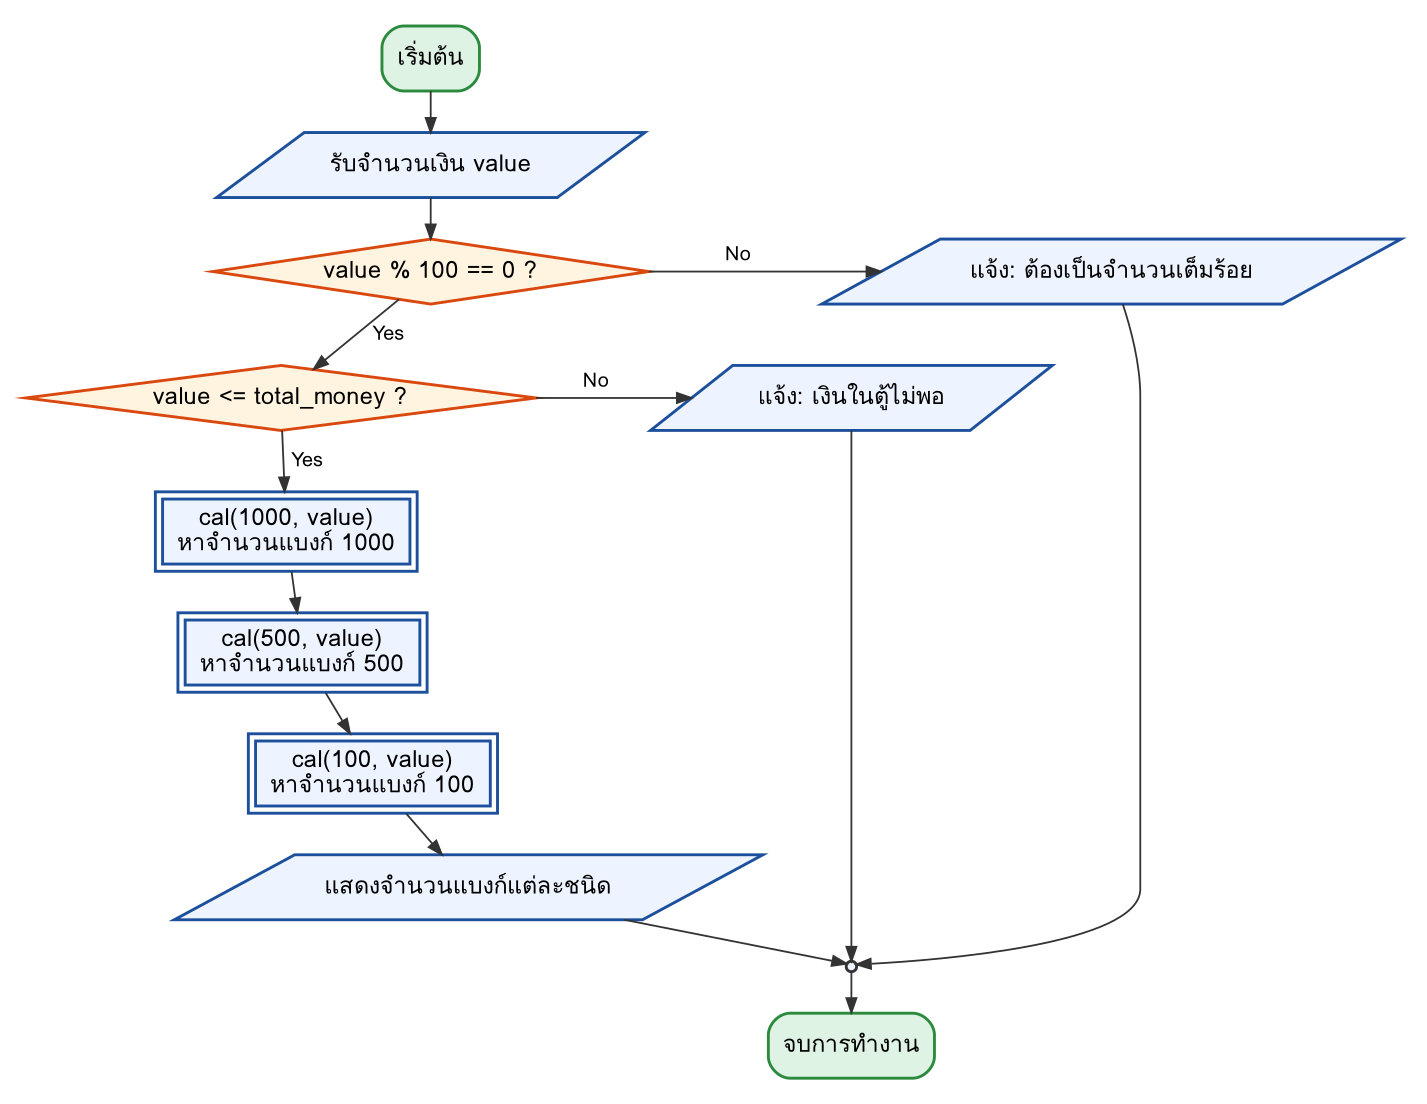<br><b>แผนภาพ</b> ผังงานโปรแกรมตู้ ATM</p>

### แบบที่ 1: เขียนแบบทั่วไป (ไม่ใช้ฟังก์ชัน)
หลักการคำนวณ
- **จำนวนธนบัตรที่ต้องจ่าย** = ยอดเงินที่พิจารณา ÷ มูลค่าธนบัตร (ตัดเศษทิ้ง) เช่น 5500 / 1000 = 5.5 ตัดเศษได้ **5 ใบ**
- **จำนวนเงินที่เหลือ** = ยอดเงินที่พิจารณา − (จำนวนธนบัตรที่จ่าย × มูลค่าธนบัตร) เช่น 5500 − 5×1000 = **500** บาท แล้วนำไปพิจารณาธนบัตรมูลค่าถัดไป

> ⚠️ ต้นฉบับใช้ `sys.exit(0)` เพื่อจบโปรแกรม ซึ่งใน Jupyter จะแสดงข้อความ `SystemExit` ใน Notebook นี้จึงจัดโค้ดด้วย `if…else` แทน ผลลัพธ์เหมือนเดิม

In [ ]:
# atm.py
bank_1000 = 10
bank_500 = 20
bank_100 = 30

pay_1000 = 0
pay_500 = 0
pay_100 = 0

total_money = (1000 * bank_1000) + \
              (500 * bank_500) + \
              (100 * bank_100)

value = int(input("Enter your amount: "))

if value % 100 == 0:
    if total_money >= value:
        # consider bank 1000
        pay_1000 = int(value / 1000)
        value = value - (pay_1000 * 1000)

        # consider bank 500
        pay_500 = int(value / 500)
        value = value - (pay_500 * 500)

        # consider bank 100
        pay_100 = int(value / 100)
        value = value - (pay_100 * 100)

        print('''
            ATM will pay bank :
                1000 : {0}
                500  : {1}
                100  : {2}\n'''.format(pay_1000, pay_500, pay_100))
    else:
        print("ATM has not enough money.")
else:
    print("Your amount must be a multiple of 100 baht.")

### แบบที่ 2: ใช้ฟังก์ชันลดความซ้ำซ้อน
สังเกตว่าการคำนวณธนบัตรทั้ง 3 ชนิดมี **รูปแบบเดียวกัน** ซ้ำกัน 3 ครั้ง จึงรวมเป็นฟังก์ชัน `cal()` ที่รับ **มูลค่าธนบัตร** และ **จำนวนเงินที่พิจารณา** แล้ว **คืนค่า 2 ค่า** คือจำนวนธนบัตรที่ต้องจ่าย และเงินที่เหลือ

In [ ]:
# atm_func.py
def cal(bank, value):
    """คำนวณจำนวนธนบัตรที่ต้องจ่าย
    @param bank  : มูลค่าธนบัตร {1000, 500, 100}
    @param value : จำนวนเงินที่พิจารณา
    @return      : (จำนวนธนบัตร, เงินที่เหลือ)"""
    pay = value // bank            # เทียบเท่า int(value / bank) สำหรับจำนวนบวก
    value = value - (pay * bank)
    return pay, value

bank_1000, bank_500, bank_100 = 10, 20, 30
total_money = (1000 * bank_1000) + (500 * bank_500) + (100 * bank_100)

value = int(input("Enter your amount: "))

if value % 100 == 0:
    if total_money >= value:
        pay_1000, value = cal(1000, value)
        pay_500, value = cal(500, value)
        pay_100, value = cal(100, value)
        print(f'''
            ATM will pay bank :
                1000 : {pay_1000}
                500  : {pay_500}
                100  : {pay_100}\n''')
    else:
        print("ATM has not enough money.")
else:
    print("Your amount must be a multiple of 100 baht.")

<div style="border-left:5px solid #d9480f;padding:8px 14px;background:rgba(217,72,15,.08)">

### ⚠️ ข้อบกพร่องที่ซ่อนอยู่: ตู้มีแบงก์ 1,000 แค่ 10 ใบ!
ลองป้อน **15,000** บาท ซึ่งไม่เกินเงินในตู้ (23,000) โปรแกรมทั้งสองแบบจะสั่งจ่ายแบงก์ 1,000 จำนวน **15 ใบ** ทั้งที่ตู้มีเพียง **10 ใบ** เพราะโปรแกรมตรวจแค่ยอดเงินรวม ไม่ได้ตรวจ **จำนวนธนบัตรที่มีจริง** นี่คือตัวอย่างว่าทำไมการ **ทดสอบหลายกรณี** (บทที่ 2) จึงสำคัญ

**วิธีแก้:** จ่ายธนบัตรไม่เกินจำนวนที่มี (`min(value // bank, available)`) และถ้าสุดท้ายยังมีเงินเหลือ แสดงว่าจ่ายไม่ได้ เมื่อแยกเป็นฟังก์ชันแล้ว การแก้ไขก็ทำที่ฟังก์ชันเดียว ซึ่งคือข้อดีของการออกแบบด้วยฟังก์ชัน
</div>

In [ ]:
# atm_v3.py: แยกงานเป็นฟังก์ชัน + ตรวจจำนวนธนบัตรที่มีจริง
def cal(bank, value, available):
    """จ่ายธนบัตรมูลค่า bank ให้มากที่สุดแต่ไม่เกินจำนวนที่มี (available)"""
    pay = min(value // bank, available)
    return pay, value - pay * bank

def withdraw(amount, stock):
    """คำนวณการจ่ายเงิน คืนค่า (dict จำนวนธนบัตรที่จ่าย, ข้อความ)
    stock คือ dict {มูลค่าธนบัตร: จำนวนใบในตู้}"""
    if amount <= 0 or amount % 100 != 0:
        return None, "จำนวนเงินต้องเป็นจำนวนเต็มร้อยและมากกว่า 0"
    if amount > sum(b * n for b, n in stock.items()):
        return None, "เงินในตู้ไม่พอ"
    payout, remain = {}, amount
    for bank in sorted(stock, reverse=True):          # พิจารณามูลค่าสูงก่อน
        payout[bank], remain = cal(bank, remain, stock[bank])
    if remain != 0:
        return None, "ตู้ไม่มีธนบัตรพอสำหรับจำนวนนี้"
    for bank, n in payout.items():                     # หักธนบัตรออกจากตู้
        stock[bank] -= n
    return payout, "สำเร็จ"

def show(amount, result):
    payout, msg = result
    print(f"ถอน {amount:>6,} บาท -> {msg}", end="")
    if payout:
        print(" | " + ", ".join(f"{b}x{n}" for b, n in payout.items() if n))
    else:
        print()

START = {1000: 10, 500: 20, 100: 30}

print("=== ทดสอบแต่ละกรณีกับตู้ที่เติมเงินเต็ม ===")
for amount in [5800, 15000, 250, 23000, 30000]:
    show(amount, withdraw(amount, dict(START)))      # dict(START) = สำเนาตู้ใหม่ทุกครั้ง

print("\n=== กรณีจ่ายไม่ได้แม้เงินรวมพอ ===")
show(1500, withdraw(1500, {1000: 10, 500: 0, 100: 2}))

print("\n=== ถอนต่อเนื่องจากตู้เดียวกัน ===")
stock = dict(START)
for amount in [9000, 9000, 4000, 1500]:
    show(amount, withdraw(amount, stock))
print("ธนบัตรคงเหลือในตู้:", stock)

In [ ]:
# ลองใช้งานกับข้อมูลจริงจากผู้ใช้
stock = {1000: 10, 500: 20, 100: 30}
amount = int(input("Enter your amount: "))
show(amount, withdraw(amount, stock))

<a id="s88"></a>
## 8.8 สรุป
- ฟังก์ชันในภาษาโปรแกรมมี 2 ประเภท คือ **ฟังก์ชันที่มีอยู่ในภาษา (Built-in Function)** เช่น `print()`, `input()` และ **ฟังก์ชันที่ผู้ใช้สร้างเอง (User-defined Function)** ตามหลักไวยากรณ์ `def ชื่อ(พารามิเตอร์):`
- **ฟังก์ชัน** คือกลุ่มคำสั่งที่ทำหน้าที่เฉพาะอย่าง แยกการทำงานออกจากโปรแกรมอย่างอิสระ และทำงานเมื่อถูกเรียกใช้
- การแบ่งโค้ดเป็นฟังก์ชันตามหน้าที่ **ลดความซ้ำซ้อน** เรียกใช้ได้จากทุกส่วนของโปรแกรม และ **แก้ไขส่วนหนึ่งได้โดยไม่กระทบส่วนอื่น**
- **Docstring** คือสตริงแรกหลังส่วนหัวของฟังก์ชัน ใช้อธิบายสิ่งที่ฟังก์ชันทำ ดูได้ด้วย `__doc__` หรือ `help()`
- คำสั่ง **`return`** ส่งผลลัพธ์ออกจากฟังก์ชัน ซึ่งไพธอน **ส่งได้มากกว่า 1 ค่า** และฟังก์ชันที่ไม่มี `return` จะคืน `None`
- **ตัวแปร Local** อยู่ในฟังก์ชันและถูกทำลายเมื่อฟังก์ชันจบ ส่วน **ตัวแปร Global** อ่านได้ทุกที่ แต่ต้องประกาศ `global` จึงจะแก้ไขจากในฟังก์ชันได้
- **พารามิเตอร์** คือตัวแปรในส่วนหัวของฟังก์ชัน ส่วน **อาร์กิวเมนต์** คือค่าที่ส่งเข้าไปตอนเรียกใช้
- การส่งอาร์กิวเมนต์โดยทั่วไปมี 2 แบบ คือ **Pass by Value** (ส่งสำเนา จึงไม่กระทบข้างนอก) และ **Pass by Reference** (ส่งที่อยู่ จึงเร็วแต่กระทบข้างนอกได้) ส่วนไพธอนใช้แบบ **Pass by Object Reference** คือการแก้ไขข้างในวัตถุที่แก้ไขได้ (เช่น ลิสต์) จะกระทบผู้เรียก แต่การกำหนดค่าใหม่หรือข้อมูลชนิดที่แก้ไขไม่ได้จะไม่กระทบ
- ประเภทอาร์กิวเมนต์: **Required** (ตามตำแหน่ง ต้องครบ), **Keyword** (`ชื่อ=ค่า`), **Default** (มีค่าปริยาย), **Variable-length** (`*args`, `**kwargs`)
- **ฟังก์ชันแบบเวียนเกิด** เรียกตัวเอง ต้องมีกรณีฐานเสมอ ทำให้โค้ดสั้นและใกล้นิยามคณิตศาสตร์ แต่อาจเปลืองหน่วยความจำและช้ากว่าการวนซ้ำ

<a id="s89"></a>
## 8.9 คำถามท้ายบท
1. จงอธิบายความหมายของพารามิเตอร์และอาร์กิวเมนต์
2. จงอธิบายความหมาย ขอบเขตการอ้างอิง และลักษณะการใช้งานของตัวแปรแบบ Local Variable และ Global Variable
3. จงอธิบายลักษณะ ความแตกต่าง ข้อดีและข้อเสียของการส่งผ่านอาร์กิวเมนต์แบบ Pass by Reference และ Pass by Value
4. จงเขียนฟังก์ชันหาผลรวมของสมาชิกในลิสต์ เช่น `(8, 2, 3, 0, 7)` ได้ `20`
5. จงเขียนฟังก์ชันกลับสตริงจากหน้าไปหลัง เช่น `"1234abcd"` ได้ `"dcba4321"`
6. จงเขียนฟังก์ชันตัดค่าซ้ำในลิสต์ เช่น `[1,2,3,3,3,3,4,5]` ได้ `[1, 2, 3, 4, 5]` และ `['a','b','c','c','c','a','d','e','e']` ได้ `['a','b','c','d','e']`
7. จงเขียนฟังก์ชันรับจำนวนเต็ม แล้วตรวจสอบว่าเป็นจำนวนเฉพาะหรือไม่ ถ้าใช่คืนค่า `True` ไม่ใช่คืนค่า `False`
8. จงเขียนฟังก์ชันรับสตริงที่เป็นคำผสมเชื่อมด้วยยัติภังค์ (`-`) แล้วเรียงคำใหม่ตามตัวอักษร เช่น `green-red-yellow-black-white` ได้ `black-green-red-white-yellow`
9. จงเขียนฟังก์ชันรับสตริงภาษาอังกฤษ แล้วนับจำนวนตัวพิมพ์ใหญ่และตัวพิมพ์เล็ก เช่น `'The quick Brow Fox'` ได้ตัวพิมพ์ใหญ่ 3 ตัว ตัวพิมพ์เล็ก 12 ตัว
10. จงเขียนฟังก์ชันรับจำนวนนาที แล้วแสดงผลในรูปแบบ ชั่วโมง : นาที

### ✏️ คำตอบข้อ 1–3
**ชื่อ–สกุล:** ............................  **รหัสนักศึกษา:** ............................

1.
2.
3.

### 💻 ข้อ 4–10: เขียนฟังก์ชันแล้วรันเซลล์ตรวจคำตอบ
- ข้อ 6 ให้ **คงลำดับการพบครั้งแรก** ไว้ (ระวัง: `list(set(...))` อาจทำให้ลำดับเปลี่ยน)
- ข้อ 9 คืนค่าทูเพิล `(จำนวนตัวพิมพ์ใหญ่, จำนวนตัวพิมพ์เล็ก)`
- ข้อ 10 คืนค่าสตริงรูปแบบ `"ชั่วโมง:นาที"` โดยนาทีเป็นเลข 2 หลักเสมอ เช่น `minutes_to_hm(135)` → `"2:15"` และ `minutes_to_hm(65)` → `"1:05"`

In [ ]:
def list_sum(items):            # ข้อ 4 (ห้ามใช้ sum() ฝึกเขียนลูปเอง)
    pass

def reverse_string(s):          # ข้อ 5
    pass

def unique(items):              # ข้อ 6
    pass

def is_prime(n):                # ข้อ 7
    pass

def sort_hyphen_words(s):       # ข้อ 8
    pass

def count_case(s):              # ข้อ 9
    pass

def minutes_to_hm(minutes):     # ข้อ 10
    pass

In [ ]:
# ✅ เซลล์ตรวจคำตอบ
import io as _io, contextlib as _cl
def _capture(func, *args):
    _buf = _io.StringIO()
    try:
        with _cl.redirect_stdout(_buf):
            func(*args)
    except Exception as _e:
        return f"เกิดข้อผิดพลาด: {_e}"
    return _buf.getvalue()
def _safe(f, *a):
    try:
        return f(*a)
    except Exception as _e:
        return f"เกิดข้อผิดพลาด: {type(_e).__name__}: {_e}"
_tests = [
    ("list_sum((8, 2, 3, 0, 7))", _safe(list_sum, (8, 2, 3, 0, 7)), 20),
    ("list_sum([])", _safe(list_sum, []), 0),
    ("reverse_string('1234abcd')", _safe(reverse_string, "1234abcd"), "dcba4321"),
    ("unique([1,2,3,3,3,3,4,5])", _safe(unique, [1, 2, 3, 3, 3, 3, 4, 5]), [1, 2, 3, 4, 5]),
    ("unique(['a','b','c','c','c','a','d','e','e'])", _safe(unique, list("abccca" "dee")), ["a", "b", "c", "d", "e"]),
    ("unique([3,1,3,2,1])", _safe(unique, [3, 1, 3, 2, 1]), [3, 1, 2]),
    ("is_prime(2)", _safe(is_prime, 2), True),
    ("is_prime(1)", _safe(is_prime, 1), False),
    ("is_prime(97)", _safe(is_prime, 97), True),
    ("is_prime(91)", _safe(is_prime, 91), False),
    ("sort_hyphen_words(...)", _safe(sort_hyphen_words, "green-red-yellow-black-white"), "black-green-red-white-yellow"),
    ("count_case('The quick Brow Fox')", _safe(count_case, "The quick Brow Fox"), (3, 12)),
    ("minutes_to_hm(135)", _safe(minutes_to_hm, 135), "2:15"),
    ("minutes_to_hm(65)", _safe(minutes_to_hm, 65), "1:05"),
    ("minutes_to_hm(45)", _safe(minutes_to_hm, 45), "0:45"),
]
_ok = 0
for _label, _got, _exp in _tests:
    _pass = _got == _exp
    _ok += _pass
    _show = repr(_got) if len(repr(_got)) < 70 else repr(_got)[:67] + "..."
    print(f"{'✅' if _pass else '❌'} {_label} = {_show}" + ("" if _pass else f"\n      ควรได้ {_exp!r}"[:200]))
print(f"\nผ่าน {_ok}/{len(_tests)} ข้อ" + ("  🎉" if _ok == len(_tests) else ""))

<details><summary><b>🔑 แนวคำตอบ (คลิกเพื่อดูหลังจากทำเองแล้ว)</b></summary>

**ข้อ 1.** พารามิเตอร์คือตัวแปรที่ประกาศในส่วนหัวของฟังก์ชันเพื่อรับค่า ส่วนอาร์กิวเมนต์คือค่าจริงที่ส่งให้ฟังก์ชันตอนเรียกใช้ เช่น `def f(x)` (x คือพารามิเตอร์) และ `f(5)` (5 คืออาร์กิวเมนต์)

**ข้อ 2.** Local คือตัวแปรที่กำหนดในฟังก์ชัน มองเห็นได้เฉพาะในฟังก์ชันนั้น และมีชีวิตเฉพาะตอนฟังก์ชันทำงาน ใช้เก็บค่าชั่วคราวระหว่างคำนวณ ส่วน Global คือตัวแปรที่กำหนดนอกฟังก์ชัน มองเห็นได้ทั้งโปรแกรม อ่านจากในฟังก์ชันได้ แต่ต้องประกาศ `global` ก่อนแก้ไข เหมาะกับค่าคงที่ที่ใช้ร่วมกัน เช่น อัตราภาษี

**ข้อ 3.** Pass by Value ส่งสำเนาของค่า ข้อดีคือปลอดภัยเพราะไม่กระทบข้อมูลต้นฉบับ ข้อเสียคือเสียเวลาและหน่วยความจำในการคัดลอก ส่วน Pass by Reference ส่งที่อยู่อ้างอิง ข้อดีคือเร็วและประหยัดหน่วยความจำ ข้อเสียคือฟังก์ชันอาจแก้ไขข้อมูลต้นฉบับโดยไม่ตั้งใจ (ไพธอนใช้ Pass by Object Reference ดูหัวข้อ 8.4)

```python
def list_sum(items):
    total = 0
    for x in items:
        total += x
    return total

def reverse_string(s):
    return s[::-1]

def unique(items):
    result = []
    for x in items:
        if x not in result:
            result.append(x)
    return result

def is_prime(n):
    if n < 2:
        return False
    for d in range(2, int(n ** 0.5) + 1):
        if n % d == 0:
            return False
    return True

def sort_hyphen_words(s):
    return "-".join(sorted(s.split("-")))

def count_case(s):
    upper = lower = 0
    for ch in s:
        if ch.isupper():
            upper += 1
        elif ch.islower():
            lower += 1
    return upper, lower

def minutes_to_hm(minutes):
    return f"{minutes // 60}:{minutes % 60:02d}"
```
</details>

### 🏆 แบบทดสอบท้ายบท (ตรวจคะแนนอัตโนมัติ)
รันเซลล์ด้านล่าง แล้วพิมพ์ตัวเลือก (ก/ข/ค/ง) ของแต่ละข้อ

In [ ]:
quiz = [
    ("คำหลักใดใช้นิยามฟังก์ชันในไพธอน",
     ["ก. function", "ข. def", "ค. func", "ง. define"], "ข"),
    ("ฟังก์ชันที่ไม่มีคำสั่ง return จะคืนค่าใด",
     ["ก. 0", "ข. False", "ค. None", "ง. ''"], "ค"),
    ("ใน def area(w, h): ตัวแปร w และ h เรียกว่าอะไร",
     ["ก. อาร์กิวเมนต์", "ข. พารามิเตอร์", "ค. docstring", "ง. global"], "ข"),
    ("ตัวแปรที่กำหนดค่าภายในฟังก์ชันมีขอบเขตแบบใด",
     ["ก. Global", "ข. Local", "ค. Public", "ง. Static"], "ข"),
    ("คำหลักใดใช้เมื่อต้องการแก้ไขตัวแปรภายนอกจากในฟังก์ชัน",
     ["ก. global", "ข. extern", "ค. public", "ง. outside"], "ก"),
    ("def f(a, b=2): return a * b แล้ว f(5) ได้ผลเท่าใด",
     ["ก. 5", "ข. 7", "ค. 10", "ง. Error"], "ค"),
    ("def g(*args): return len(args) แล้ว g(1, 2, 3) ได้ผลเท่าใด",
     ["ก. 1", "ข. 3", "ค. 6", "ง. Error"], "ข"),
    ("def h(x): x.append(9) และ L = [1]; h(L) แล้ว L มีค่าเท่าใด",
     ["ก. [1]", "ข. [9]", "ค. [1, 9]", "ง. Error"], "ค"),
    ("ส่วนใดที่ฟังก์ชันเวียนเกิดต้องมีเพื่อไม่ให้เรียกตัวเองไม่สิ้นสุด",
     ["ก. docstring", "ข. กรณีฐาน (base case)", "ค. global", "ง. *args"], "ข"),
    ("ข้อใดเรียกใช้ฟังก์ชัน info(name, age) ด้วย keyword arguments",
     ["ก. info('A', 20)", "ข. info(age=20, name='A')", "ค. info[name='A']", "ง. def info(age=20)"], "ข"),
]

def run_quiz():
    score = 0
    for i, (q, choices, ans) in enumerate(quiz, 1):
        print(f"\nข้อ {i}. {q}")
        for c in choices:
            print("   ", c)
        reply = input("คำตอบ (ก/ข/ค/ง): ").strip()
        if reply == ans:
            print("   ✅ ถูกต้อง"); score += 1
        else:
            print(f"   ❌ ยังไม่ถูก คำตอบที่ถูกคือ {ans}")
    print(f"\n🎯 คะแนนของคุณ: {score}/{len(quiz)}")
    print("🏆 ยอดเยี่ยม!" if score == len(quiz) else "👍 ดีมาก" if score >= 7 else "📖 ทบทวนเนื้อหาอีกครั้งนะ")

run_quiz()

<a id="s810"></a>
## 8.10 บรรณานุกรม
- Chun, W. J. (2007). *Core Python Programming* (2nd ed.). United States of America: Prentice Hall PTR.
- Matthes, E. (2015). *Python Crash Course: A Hands-On, Project-Based Introduction to Programming.* United States of America: No Starch Press.
- Python 3 – Functions. Retrieved Oct 10, 2016, from https://www.tutorialspoint.com/python3/python_functions.htm
- Python Functions. Retrieved Oct 10, 2016, from https://www.programiz.com/python-programming/function
- Python functions [20 exercises with solution]. Retrieved Oct 10, 2016, from https://www.w3resource.com/python-exercises/python-functions-exercises.php

**แหล่งข้อมูลเพิ่มเติม**
- Python Software Foundation. *Defining Functions (Tutorial).* https://docs.python.org/3/tutorial/controlflow.html#defining-functions
- Python Software Foundation. *Programming FAQ: How do I write a function with output parameters (call by reference)?* https://docs.python.org/3/faq/programming.html#how-do-i-write-a-function-with-output-parameters-call-by-reference

<sub>หมายเหตุ: ผังงานตู้ ATM วาดขึ้นใหม่ตามต้นฉบับในเอกสารประกอบการสอน และแผนภาพการเรียกใช้ฟังก์ชันจัดทำขึ้นเพิ่มเติม</sub>

---
<p align="center"><b>จบบทที่ 8</b> · บทต่อไป: <b>บทที่ 9 NumPy</b></p>